# Extra 5 - Convolutional networks: learning the features of a sequence

**AI in Quantitative Biology (Univ. Milano, 2026) - supplementary notebook**
*Goes with the slides of **Part II: Advanced ANN architectures** (deck pages 27-46).*

In classes 1 and 2 the inputs were already numbers: a handful of descriptors per molecule, fed to a dense
network. Biology rarely hands us numbers. It hands us **sequences, structures, images, graphs** -
objects of varying size and no natural coordinates. The slides call the step that turns them into
fixed-length vectors **featurization**, and the central claim of Part II is that we should stop
hand-crafting that step and let the network **learn the features** instead. Today we test that claim
on a real problem, with architectures chosen to match the shape of the data:

* a **convolutional** network, which assumes the useful patterns are *local motifs* that can occur
  anywhere (deck pp. 29-32);
* a **recurrent** network, which reads the sequence one symbol at a time and remembers (p. 33).

The task: a protein's N-terminus carries an **address label** that tells the cell where to send it.
**SP** = signal peptide (secretory pathway), **mTP** = mitochondrial transit peptide, **other** = no
signal. Neither signal has a fixed motif; both are recognised by a physico-chemical *pattern along
the chain*. We will see a convolutional filter rediscover one of those patterns from scratch.

| Part | Topic | Time |
|---|---|---|
| 1 | Featurization: a sequence becomes a tensor | 10 min |
| 2 | Dense vs convolutional: learning the features | 20 min |
| 3 | Opening the black box: what the filters learned | 15 min |
| 4 | Convolution vs recurrence, head to head | 10 min |
| 5 | Control: does the order actually matter? | 10 min |
| 6 | Where this is going: transformers | 5 min |

Everything runs on a laptop **CPU** in a few minutes. Exercises are marked ✏️ and open questions ❓;
the answers are in this notebook, right below - try before you read.

## Setup

The cell below is collapsed on purpose: it only contains imports, the data loader and a few
helpers. Run it and move on (click the title to unfold it if you are curious).

In [ ]:
# @title Setup: imports, data loading and helpers (run me)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RNG = 0                                      # fixed seed: everyone gets the same numbers
pd.set_option("display.precision", 3)


def find_data_dir():
    """$QBIO_DATA if set, else the `data/` folder of the course repository (here or above)."""
    if os.environ.get("QBIO_DATA"):
        return Path(os.environ["QBIO_DATA"])
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data" / "targeting.tsv").exists():
            return p / "data"
    raise FileNotFoundError("Cannot find data/: run the notebook inside the course repository, "
                            "or set QBIO_DATA to the path of its data/ folder")


DATA_DIR = find_data_dir()
print("data from", DATA_DIR)


def load_targeting():
    """3600 protein N-termini (first 50 residues) labelled SP / mTP / other."""
    return pd.read_csv(DATA_DIR / "targeting.tsv", sep="\t")


def load_enzymes():
    """2047 enzymes with their EC class (1-6) and full sequence."""
    return pd.read_csv(DATA_DIR / "enzymes.tsv", sep="\t")


AA = "ACDEFGHIKLMNPQRSTVWY"                  # the 20 standard amino acids
AA_INDEX = {a: i for i, a in enumerate(AA)}

# Kyte-Doolittle hydropathy scale (positive = hydrophobic). Used only to *interpret* the models.
KYTE_DOOLITTLE = {
    "A": 1.8, "R": -4.5, "N": -3.5, "D": -3.5, "C": 2.5, "Q": -3.5, "E": -3.5,
    "G": -0.4, "H": -3.2, "I": 4.5, "L": 3.8, "K": -3.9, "M": 1.9, "F": 2.8,
    "P": -1.6, "S": -0.8, "T": -0.7, "W": -0.9, "Y": -1.3, "V": 4.2,
}
KD = np.array([KYTE_DOOLITTLE[a] for a in AA])


def aa_composition(seq):
    """Fraction of each of the 20 amino acids in `seq` (a 20-vector, sums to 1)."""
    v = np.zeros(20, dtype=np.float32)
    for a in seq:
        v[AA_INDEX[a]] += 1
    return v / max(len(seq), 1)


def one_hot(seq):
    """A length-L sequence -> an (L, 20) matrix of 0s with a single 1 per column."""
    m = np.zeros((len(seq), 20), dtype=np.float32)
    m[np.arange(len(seq)), [AA_INDEX[a] for a in seq]] = 1
    return m

data from /Users/toni/Sync/teaching/c-courses/2026 AI QBio/classes/data


In [ ]:
import torch
import torch.nn as nn

torch.manual_seed(RNG)
torch.set_num_threads(2)                     # keeps timings comparable between laptops
print("PyTorch", torch.__version__)

PyTorch 2.15.0


In [ ]:
# @title Support code: the generic training loop and the plotting helpers (run me)
from sklearn.metrics import confusion_matrix


def accuracy(model, X, Y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(dim=1) == Y).float().mean().item()


def train(model, X_tr, Y_tr, X_te, Y_te, epochs=15, lr=0.01, batch_size=64, seed=RNG):
    """Minibatch Adam on the cross-entropy loss - the loop written out in `extra03`.

    Returns a DataFrame with the train/test accuracy after every epoch. We look at the test set
    every epoch for teaching only; in a real project that is a validation set, and the test set is
    touched once, at the very end.
    """
    torch.manual_seed(seed)
    optimiser = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        order = torch.randperm(len(X_tr))
        for start in range(0, len(order), batch_size):
            batch = order[start:start + batch_size]
            loss = loss_fn(model(X_tr[batch]), Y_tr[batch])
            optimiser.zero_grad()            # forget the previous gradients
            loss.backward()                  # d(loss)/d(weight) for every weight
            optimiser.step()                 # nudge the weights downhill
        history.append({"epoch": epoch,
                        "train accuracy": accuracy(model, X_tr, Y_tr),
                        "test accuracy": accuracy(model, X_te, Y_te)})
    return pd.DataFrame(history).set_index("epoch")


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def plot_confusion(y_true, y_pred, labels, title=""):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    fig, ax = plt.subplots(figsize=(4, 3.6))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(labels)), labels); ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=10)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=9)
    plt.tight_layout()
    return ax


def plot_filter(W, f, ax, title=None):
    """Heatmap of convolution filter number f: its (20, width) weight matrix."""
    w = W[f]
    lim = np.abs(W).max()
    im = ax.imshow(w, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_yticks(range(20), list(AA), fontsize=6)
    ax.set_xticks(range(w.shape[1]), [str(i + 1) for i in range(w.shape[1])], fontsize=6)
    ax.set_title(title or f"filter {f}", fontsize=9)
    return im

## Part 1 - Featurization: a sequence becomes a tensor

> *"What if the inputs are not a set of real numbers? We need to devise a featurization to convert
> arbitrary objects to (fixed length) vectors."* (deck p. 25)

**3600 proteins** from UniProtKB/Swiss-Prot, 1200 per class, from five organisms. We keep only the
**first 50 residues** (`nterm`); `signal_len` is the annotated length of the signal (0 for *other*).

In [ ]:
tp = load_targeting()
LABELS = ["other", "SP", "mTP"]
display(tp.head(3))
print(tp["label"].value_counts().to_dict())
print(tp["nterm"].str.len().unique(), "residues per sequence")

,accession,entry_name,protein_name,organism,label,signal_len,nterm
0,A0A023PYC6,YA16A_YEAST,Putative uncharacterized membrane protein YAL0...,Saccharomyces cerevisiae,SP,25,MVSSFFMASTLLAISSCFNSSISRAKGYNDSLESESLEFDVVDVVD...
1,A0A075B6J1,LV537_HUMAN,Immunoglobulin lambda variable 5-37,Homo sapiens,SP,19,MAWTPLLLLLLSHCTGSLSQPVLTQPPSSSASPGESARLTCTLPSD...
2,A0A075B6J6,LV322_HUMAN,Immunoglobulin lambda variable 3-22,Homo sapiens,SP,20,MAWATLLLPLLNLYTGSVASYELTQLPSVSVSPGQTARITCSGDVL...


{'SP': 1200, 'mTP': 1200, 'other': 1200}
[50] residues per sequence


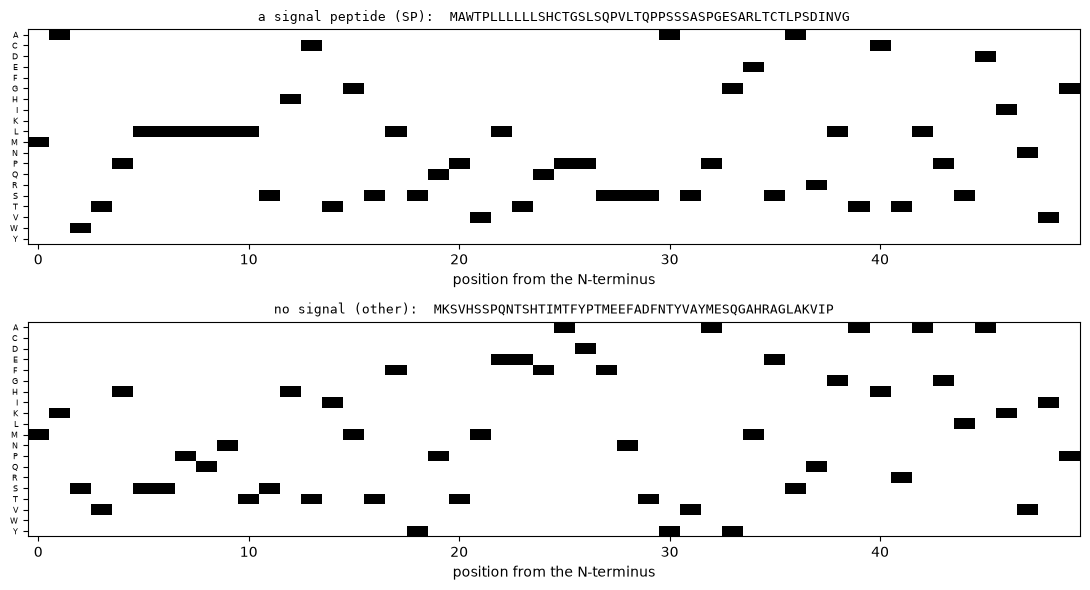

In [ ]:
example_sp = tp.loc[tp["label"] == "SP", "nterm"].iloc[1]
example_ot = tp.loc[tp["label"] == "other", "nterm"].iloc[0]

fig, axes = plt.subplots(2, 1, figsize=(11, 6))
for ax, seq, name in [(axes[0], example_sp, "a signal peptide (SP)"),
                      (axes[1], example_ot, "no signal (other)")]:
    ax.imshow(one_hot(seq).T, cmap="Greys", aspect="auto", interpolation="nearest")
    ax.set_yticks(range(20), list(AA), fontsize=6)
    ax.set_title(f"{name}:  {seq}", fontsize=9, family="monospace")
    ax.set_xlabel("position from the N-terminus")
plt.tight_layout()

In [ ]:
X_all = torch.tensor(np.stack(tp["nterm"].map(one_hot)))      # (3600, 50, 20)
y_all = tp["label"].map({lab: i for i, lab in enumerate(LABELS)}).values
Y_all = torch.tensor(y_all)
print("X_all:", tuple(X_all.shape), " = proteins x positions x amino acids")
print(f"{X_all.numel():,} numbers, of which {int(X_all.sum()):,} are non-zero "
      f"({100 * X_all.mean():.0f}%)")

X_all: (3600, 50, 20)  = proteins x positions x amino acids
3,600,000 numbers, of which 180,000 are non-zero (5%)


❓ One-hot encoding is 95% zeros. Is that a problem?

**Answer.** Not in itself - it is the honest encoding of a categorical variable, and the first layer
of the network immediately turns each sparse 20-vector into a dense one (that is exactly what an
*embedding* layer is: a lookup table of learned vectors, equivalent to a linear layer applied to a
one-hot). What *is* a problem is the **size**: 50 × 20 = 1000 inputs per protein, and a full protein
of 400 residues would need 8000. Part 2 is about an architecture that copes with that.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

idx_train, idx_test = train_test_split(np.arange(len(tp)), test_size=0.25,
                                       stratify=y_all, random_state=RNG)
X_train, Y_train = X_all[idx_train], Y_all[idx_train]
X_test, Y_test = X_all[idx_test], Y_all[idx_test]

X_comp = np.vstack(tp["nterm"].map(aa_composition))           # (3600, 20)
logreg = LogisticRegression(max_iter=3000).fit(X_comp[idx_train], y_all[idx_train])
ACC_COMP = accuracy_score(y_all[idx_test], logreg.predict(X_comp[idx_test]))
print(f"composition (20 features) + logistic regression: test accuracy = {ACC_COMP:.3f}")

composition (20 features) + logistic regression: test accuracy = 0.802


0.802 from 20 hand-made numbers and 63 fitted parameters. That is the number every architecture
below has to beat.

## Part 2 - Dense vs convolutional: learning the features

### First try: just make the network deep

> *"ANNs with more than 2-3 hidden layers are called deep. In principle they may learn more
> 'abstract' concepts. However, lots of data and computing power is needed."* (deck p. 28)

The obvious move is to flatten the 50 × 20 matrix into 1000 inputs and put a dense (fully connected)
hidden layer on top - exactly the architecture of classes 1 and 2, just much wider.

In [ ]:
class DenseNet(nn.Module):
    """Flatten the 50x20 matrix and feed it to a dense hidden layer."""
    def __init__(self, hidden=32):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(),          # (batch, 50, 20) -> (batch, 1000)
                                 nn.Linear(50 * 20, hidden), nn.ReLU(),
                                 nn.Linear(hidden, len(LABELS)))

    def forward(self, x):
        return self.net(x)


torch.manual_seed(RNG)
dense = DenseNet(hidden=32)
print(n_params(dense), "parameters")
hist_dense = train(dense, X_train, Y_train, X_test, Y_test, epochs=15)
print(hist_dense.tail(3))

32131 parameters


       train accuracy  test accuracy
epoch                               
13                1.0          0.857
14                1.0          0.857
15                1.0          0.857


❓ 32 131 parameters, and the training accuracy hits 1.000. Why is the test accuracy only ≈ 0.86?

**Answer.** The dense layer has a **separate weight for every (position, amino acid) pair**. A
leucine at position 7 and a leucine at position 12 are, as far as this network is concerned, two
unrelated features: whatever it learns about one teaches it nothing about the other. Signal peptides
do not start at a fixed position - the hydrophobic core can sit anywhere between residue 4 and
residue 20 - so the network has to learn the same pattern over and over, once per position, each
time from a fraction of the data. With 2700 training proteins it instead memorises them (train
accuracy 1.000) and generalises poorly.

### The convolutional answer

> *"Featurization is a problem. How to be sure to have the 'best' features? → Learn them."*
> (deck p. 29)

A **convolutional layer** fixes the problem above by **sharing weights across positions**. One
*filter* is a small weight matrix - here 20 amino acids × 9 positions - that is slid along the
sequence; at every offset it computes a weighted sum of the 9 residues under it. The output is a
new sequence of activations, one number per offset, saying *how well this filter matches here*.
We use `n_filters` such filters in parallel, apply a ReLU, and then take, for each filter, the
**maximum over all offsets**: "the best match of this filter anywhere in the N-terminus". That
**global max-pooling** is what makes the model *translation invariant* - it does not care where the
motif is - and it also turns a variable number of offsets into a fixed-length vector, our learned
featurization. A single linear layer then maps those `n_filters` numbers to the 3 classes.

```
one-hot (50 x 20)  --[ 16 filters, width 9 ]-->  16 x 42 activations
                   --[ ReLU, max over positions ]-->  16 numbers   <- learned features
                   --[ linear ]-->  3 class scores
```

In [ ]:
class TargetingCNN(nn.Module):
    def __init__(self, n_filters=16, width=9):
        super().__init__()
        # Conv1d wants (batch, channels, length): the 20 amino acids are the input "channels"
        self.conv = nn.Conv1d(in_channels=20, out_channels=n_filters, kernel_size=width)
        self.head = nn.Linear(n_filters, len(LABELS))

    def activations(self, x):
        """(batch, n_filters, 50 - width + 1): how well each filter matches at each offset."""
        return torch.relu(self.conv(x.transpose(1, 2)))

    def forward(self, x):
        best = self.activations(x).max(dim=2).values    # global max-pooling -> (batch, n_filters)
        return self.head(best)


torch.manual_seed(RNG)
cnn = TargetingCNN(n_filters=16, width=9)
print(cnn)
print(n_params(cnn), "parameters  (vs", n_params(dense), "for the dense net)")

TargetingCNN(
  (conv): Conv1d(20, 16, kernel_size=(9,), stride=(1,))
  (head): Linear(in_features=16, out_features=3, bias=True)
)
2947 parameters  (vs 32131 for the dense net)


CNN test accuracy = 0.912


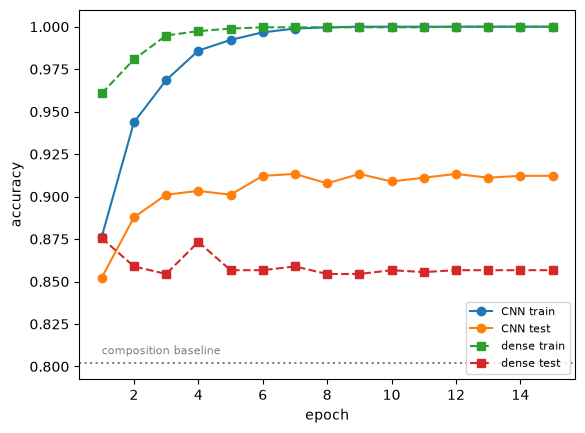

In [ ]:
hist_cnn = train(cnn, X_train, Y_train, X_test, Y_test, epochs=15)
ACC_CNN = hist_cnn["test accuracy"].iloc[-1]
print(f"CNN test accuracy = {ACC_CNN:.3f}")

ax = hist_cnn.plot(marker="o")
hist_dense.plot(marker="s", style="--", ax=ax)
ax.legend(["CNN train", "CNN test", "dense train", "dense test"], fontsize=8)
ax.axhline(ACC_COMP, color="grey", ls=":")
ax.text(1, ACC_COMP + 0.005, "composition baseline", fontsize=8, color="grey")
ax.set_ylabel("accuracy");

              precision    recall  f1-score   support

          SP      0.947     0.953     0.950       300
         mTP      0.880     0.903     0.891       300
       other      0.910     0.880     0.895       300

    accuracy                          0.912       900
   macro avg      0.912     0.912     0.912       900
weighted avg      0.912     0.912     0.912       900



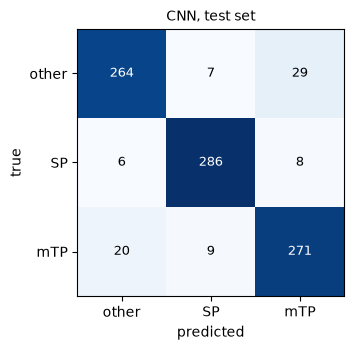

In [ ]:
cnn.eval()
with torch.no_grad():
    pred_cnn = cnn(X_test).argmax(dim=1).numpy()
names = np.array(LABELS)
print(classification_report(names[Y_test.numpy()], names[pred_cnn], digits=3))
plot_confusion(names[Y_test.numpy()], names[pred_cnn], LABELS, title="CNN, test set");

❓ The CNN has **11 times fewer parameters** than the dense net and does better. Where did the
advantage come from?

**Answer.** From the **architecture**, not from capacity. Two assumptions are built into the
convolution, and both happen to be true for targeting peptides: (i) the informative patterns are
**local** (a 9-residue window is enough to recognise a hydrophobic core), and (ii) they are
**translation invariant** (the same core counts wherever it sits). Encoding a true assumption into
the architecture - an *inductive bias* - is worth far more than extra parameters. This is the whole
point of the CNN slides: the right architecture does the feature engineering for you.
Note also where the errors are: SP is almost perfect (recall 0.953), and the largest block of
mistakes - 49 of the 79 errors - is *other* ↔ mTP, the pair that really is biologically ambiguous.

✏️ **Exercise 2.1.** The filter width is the only place where we told the network *how long* a motif
to look for. Train a CNN with `width` = 3, 5, 9, 15, 21 (16 filters each, 15 epochs, with
`torch.manual_seed(RNG)` before each) and plot accuracy against width. Where does it saturate, and
what biological length does that correspond to? (~25 s in total.)

width =  3  ( 1027 parameters)  test accuracy = 0.788


width =  5  ( 1667 parameters)  test accuracy = 0.850


width =  9  ( 2947 parameters)  test accuracy = 0.912


width = 15  ( 4867 parameters)  test accuracy = 0.928


width = 21  ( 6787 parameters)  test accuracy = 0.931


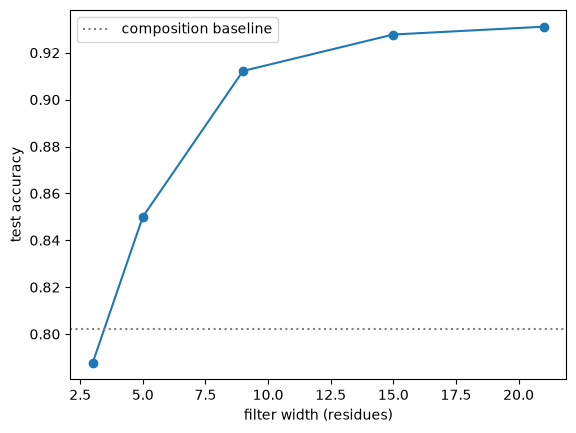

In [ ]:
widths, accs = [3, 5, 9, 15, 21], []
for w in widths:
    torch.manual_seed(RNG)
    m = TargetingCNN(n_filters=16, width=w)
    h = train(m, X_train, Y_train, X_test, Y_test, epochs=15)
    accs.append(h["test accuracy"].iloc[-1])
    print(f"width = {w:2d}  ({n_params(m):5d} parameters)  test accuracy = {accs[-1]:.3f}")

plt.plot(widths, accs, "o-")
plt.axhline(ACC_COMP, color="grey", ls=":", label="composition baseline")
plt.xlabel("filter width (residues)"); plt.ylabel("test accuracy"); plt.legend();

**Answer.** Width 3 (0.788) is *worse* than counting amino acids: a tripeptide window is too short to
see anything but local composition, and max-pooling then throws away even the counts. Accuracy climbs
steeply to width 9 (0.912) and then flattens: 15 → 0.928, 21 → 0.931. The useful motif length is
therefore **≈ 10-15 residues**, which is precisely the length of the hydrophobic h-region of a signal
peptide. The network's best hyperparameter is a measurement of the biology.

❓ Would you now simply use width 21 everywhere? Beware: the number of parameters grows linearly with
the width, the gain from 15 to 21 is within the noise of a single split, and a 21-residue filter can
no longer be read as "one motif". Width 9-15 is the honest choice.

## Part 3 - Opening the black box: what did the filters learn?

> *"The most 'useful' preprocessings for the given task will emerge from the training - automatic
> feature selection."* (deck p. 32)

That is a promise, and we can check it. Each of our 16 filters **is** a 20 × 9 weight matrix: a
position-weight-matrix-like object we can simply look at. Nothing in the data, the loss or the code
mentioned hydrophobicity, charge, or signal peptides - only the three class labels.

First, a quantitative probe. For each filter, average its weights over the 9 window positions to get
one weight per amino acid, and **correlate that with the Kyte-Doolittle hydropathy scale**. A filter
that has discovered "hydrophobic stretch" will show a high correlation. We also print the weight the
final linear layer gives each filter for each class: that tells us what the filter *votes for*.

In [ ]:
W = cnn.conv.weight.detach().numpy()          # (16, 20, 9)  filters x amino acids x window position
head_w = cnn.head.weight.detach().numpy()     # (3, 16)      class x filter

mean_w = W.mean(axis=2)                       # (16, 20): one weight per amino acid
is_pos = np.array([a in "RK" for a in AA], dtype=float)     # Arg, Lys
is_neg = np.array([a in "DE" for a in AA], dtype=float)     # Asp, Glu

table = pd.DataFrame({
    "corr with hydropathy": [np.corrcoef(mean_w[f], KD)[0, 1] for f in range(16)],
    "corr with +charge":    [np.corrcoef(mean_w[f], is_pos)[0, 1] for f in range(16)],
    "corr with -charge":    [np.corrcoef(mean_w[f], is_neg)[0, 1] for f in range(16)],
    "votes other": head_w[0], "votes SP": head_w[1], "votes mTP": head_w[2],
}).rename_axis("filter")
display(table.sort_values("corr with hydropathy", ascending=False).round(2))

,corr with hydropathy,corr with +charge,corr with -charge,votes other,votes SP,votes mTP
filter,,,,,,
10,0.93,-0.48,-0.41,-0.66,1.51,-0.96
15,0.92,-0.41,-0.45,-1.08,1.29,-0.57
0,0.85,-0.15,-0.62,-1.25,1.18,0.10
8,0.84,-0.22,-0.57,-1.20,1.11,0.35
5,0.75,-0.67,0.11,0.64,0.46,-0.84
11,0.49,0.11,-0.78,-1.29,-0.35,1.08
9,0.41,0.10,-0.94,-0.97,-0.65,1.24
3,0.29,-0.52,0.46,0.68,0.30,-0.98
13,0.13,0.24,-0.77,-0.69,-0.86,1.07


❓ Read the top of that table. What is the relationship between "looks hydrophobic" and "votes SP"?

**Answer.** The four filters most correlated with hydropathy (filters 10, 15, 0, 8; r = 0.93, 0.92,
0.85, 0.84) are **exactly** the four whose largest positive head weight is for **SP** (+1.51, +1.29,
+1.18, +1.11), and all four vote *against* "other". The network, told only "SP / mTP / other",
reinvented the **h-region** of the signal peptide - the hydrophobic core that the signal recognition
particle actually binds - and uses its presence as the evidence for SP. Nobody gave it the
Kyte-Doolittle scale; we are only using it here as a ruler to measure what it found.

Look at the bottom of the table too: the filters that vote **mTP** are the ones anti-correlated with
negative charge (filter 9: r = −0.94; filter 11: −0.78; filter 13: −0.77) and mildly positive-charge
correlated - the amphipathic, Arg/Lys-rich and Asp/Glu-depleted transit peptide.

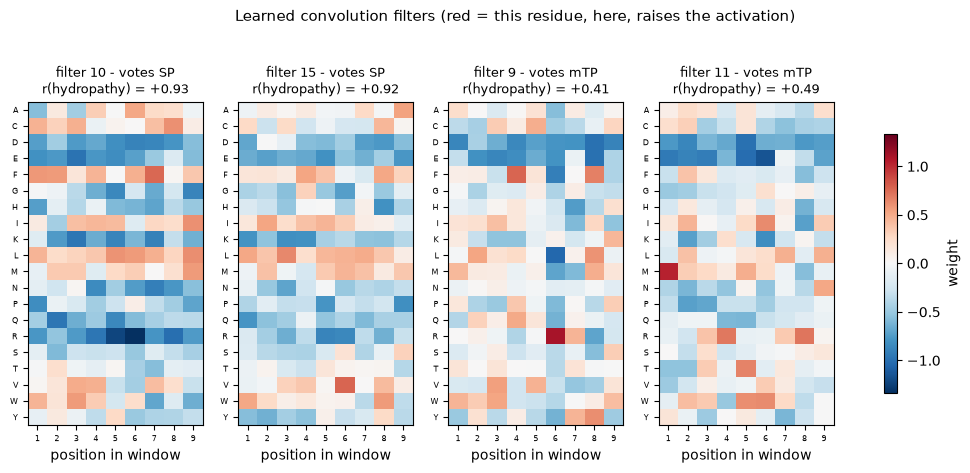

In [ ]:
# The weight matrices themselves, for the two most hydrophobic and the two most mTP-ish filters
rank_kd = np.argsort(-table["corr with hydropathy"].values)
rank_mtp = np.argsort(-head_w[2])
show = [rank_kd[0], rank_kd[1], rank_mtp[0], rank_mtp[1]]

fig, axes = plt.subplots(1, 4, figsize=(13, 4.2))
for ax, f in zip(axes, show):
    im = plot_filter(W, f, ax, title=f"filter {f} - votes {LABELS[int(np.argmax(head_w[:, f]))]}\n"
                                    f"r(hydropathy) = {table.loc[f, 'corr with hydropathy']:+.2f}")
    ax.set_xlabel("position in window")
fig.colorbar(im, ax=axes, shrink=0.8, label="weight")
fig.suptitle("Learned convolution filters (red = this residue, here, raises the activation)",
             y=1.10, fontsize=11);

Three things are readable straight off those heatmaps. The two SP filters have warm rows for L, A,
V, F, I, M and deep blue ones for D, E, K, R - "apolar here, charged nowhere". Both mTP filters have
D and E deep blue across the whole window, and filter 11 has a single bright red **M at window
position 1**: it has learned to anchor on the initiator methionine.

Still, a heatmap of weights is abstract. The most direct way to ask a filter what it detects is to
show it **the 9-mers that excite it most** across the test set - the sequence equivalent of the
famous "what image makes this unit fire" pictures of the AlexNet slide (deck p. 32).

In [ ]:
cnn.eval()
with torch.no_grad():
    A_test = cnn.activations(X_test).numpy()          # (n_test, 16, 42)
test_seqs = tp["nterm"].values[idx_test]
width = cnn.conv.kernel_size[0]

for f in show:
    where = A_test[:, f].argmax(axis=1)               # best offset per protein
    how_much = A_test[:, f].max(axis=1)
    top = np.argsort(-how_much)[:6]
    kmers = [test_seqs[i][where[i]:where[i] + width] for i in top]
    print(f"filter {f:2d} (votes {LABELS[int(np.argmax(head_w[:, f]))]:5s}): " + "  ".join(kmers))

filter 10 (votes SP   ): LCWVLLCLL  FLLLLAFLL  CLWVLLALL  ITIVLLFAM  FLCALAILL  LLLLLLLLL
filter 15 (votes SP   ): CLLLLLLLA  ALLLLVLLA  FILAILLCS  LALFLFLVA  LLLFLILAS  LLLLLLLLL
filter  9 (votes mTP  ): IWLFVRGLH  PLIPQRLMS  RVCFHRYYS  SQNFFRAYS  IYVASRRLS  LLLLLRYLV
filter 11 (votes mTP  ): MAARTLGRG  MLRTSVLRL  MLRRLLRSS  MQSRALSRL  LFSRNILRL  MATRLLRTN


❓ Read those 9-mers out loud. What are the two filter families?

**Answer.** The hydrophobic filters light up on pure apolar runs - `LCWVLLCLL`, `FLLLLAFLL`,
`CLLLLLLLA`, `ALLLLVLLA`, `LLLLLLLLL` - the h-region of a signal peptide, with no two 9-mers alike:
the filter learned a *property*, not a motif.

The mTP filters are the mirror image. Filter 11 fires on `MAARTLGRG`, `MLRTSVLRL`, `MLRRLLRSS`,
`MQSRALSRL`, `MATRLLRTN` - note that most of them *begin at the initiator methionine*, and all are
**Arg-rich**: the basic, amphipathic transit peptide, read right at the N-terminus. Filter 9 is less
photogenic (`IWLFVRGLH`, `PLIPQRLMS`, `RVCFHRYYS`, `SQNFFRAYS`) - but look again: every one of them
contains an **R** and not a single **D or E**. That is precisely its weight profile (r = −0.94 with
negative charge), and it is a real property of transit peptides, which are almost devoid of acidic
residues. A useful reminder that filters are not obliged to be human-readable concepts; some are,
some are statistical mixtures.

This is "automatic feature selection" in the literal sense: features that took biologists two decades
of experiments to describe, recovered in five seconds of CPU from 2700 labelled N-termini and nothing
else.

✏️ **Exercise 3.1.** A filter also fires *somewhere*. For the most hydrophobic filter and for the
most mTP-like one, plot the mean activation at each offset, separately for the three classes
(`A_test[Y_test == k, f].mean(axis=0)`). Where along the N-terminus does each filter find its match?

filter 10  other: peak at window start 28, mean best activation 0.33
filter 10  SP   : peak at window start  8, mean best activation 2.41
filter 10  mTP  : peak at window start 12, mean best activation 0.49
filter  9  other: peak at window start  1, mean best activation 1.13
filter  9  SP   : peak at window start  1, mean best activation 1.42
filter  9  mTP  : peak at window start  1, mean best activation 2.00


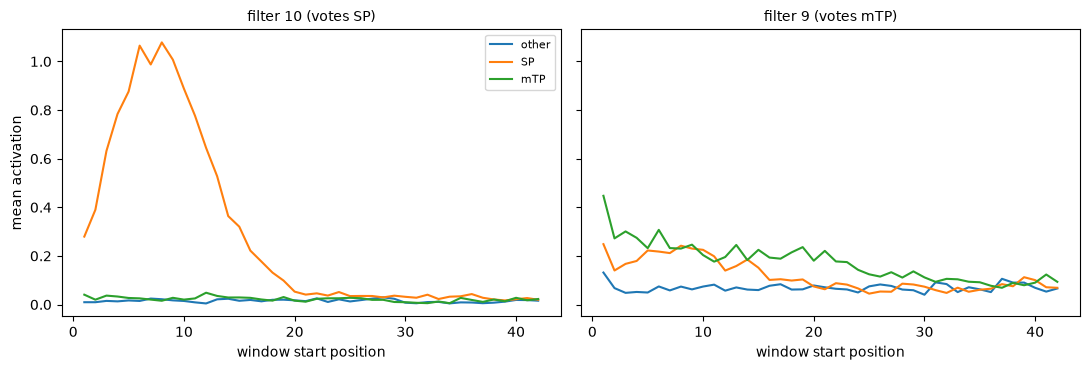

In [ ]:
y_te = Y_test.numpy()
offsets = np.arange(1, A_test.shape[2] + 1)
colours = {"other": "tab:blue", "SP": "tab:orange", "mTP": "tab:green"}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, f in zip(axes, [rank_kd[0], rank_mtp[0]]):
    for k, lab in enumerate(LABELS):
        ax.plot(offsets, A_test[y_te == k, f].mean(axis=0), color=colours[lab], label=lab)
    ax.set_title(f"filter {f} (votes {LABELS[int(np.argmax(head_w[:, f]))]})", fontsize=10)
    ax.set_xlabel("window start position")
axes[0].set_ylabel("mean activation"); axes[0].legend(fontsize=8)
plt.tight_layout()

for f in [rank_kd[0], rank_mtp[0]]:
    for k, lab in enumerate(LABELS):
        prof = A_test[y_te == k, f].mean(axis=0)
        print(f"filter {f:2d}  {lab:5s}: peak at window start {prof.argmax() + 1:2d}, "
              f"mean best activation {A_test[y_te == k, f].max(axis=1).mean():.2f}")

**Answer.** The hydrophobic filter (10) peaks at **window start 8** in SP proteins - residues 8-16,
right after the positively charged n-region - and its mean best activation there is **2.41**, against
0.49 in mTP and 0.33 in *other*: an almost binary detector, silent on the other two classes. The mTP
filter (9) peaks at **window start 1**, at the very N-terminus, but its mean best activation is 2.00
in mTP against 1.42 in SP and 1.13 in *other*: it is never silent, only *louder*. The mTP evidence is
weaker and more graded, which is exactly why mTP is the class the confusion matrix gets wrong.

Nothing forced either filter to look there: max-pooling let them use a match anywhere in the 50
residues, and they converged on positions 1-16 on their own - the window that cell biology says
carries the address.

## Part 4 - Convolution vs recurrence, head to head

> *"To address time-varying data, or sequences, we may feed the output of a neuron to itself in the
> next step."* (deck p. 33)

The convolution assumes the evidence is a **local motif**. A **recurrent** network makes a different
assumption: it reads the sequence left to right, one residue at a time, and carries a **hidden
state** $h_t$ - a vector summarising everything seen so far:

$$ h_t = f(x_t,\, h_{t-1}), \qquad t = 1,\dots,50 $$

The same $f$ (the same weights) is applied at every position - weight sharing again, but along
*time* instead of across offsets - so it too can detect a pattern wherever it occurs, and in
addition it can combine evidence from distant positions and keep track of *order*. As in class 3 we use a **GRU**
(gated recurrent unit), whose gates decide what to keep and what to forget, which makes it far easier
to train than a plain RNN. The final state $h_{50}$ goes to a linear layer.

Same data, same split, same training loop: a fair head-to-head comparison of two architectures.

In [ ]:
class TargetingGRU(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.gru = nn.GRU(input_size=20, hidden_size=hidden, batch_first=True)
        self.head = nn.Linear(hidden, len(LABELS))

    def forward(self, x):                       # x: (batch, 50, 20)
        states, h_last = self.gru(x)            # states: h_t at every position
        return self.head(h_last[-1])            # decide after the last residue

    def predict_along(self, x):
        """Class probabilities after reading 1, 2, ..., 50 residues: (batch, 50, 3)."""
        states, _ = self.gru(x)
        return torch.softmax(self.head(states), dim=-1)


torch.manual_seed(RNG)
gru = TargetingGRU(hidden=32)
print(n_params(gru), "parameters")
hist_gru = train(gru, X_train, Y_train, X_test, Y_test, epochs=15)
ACC_GRU = hist_gru["test accuracy"].iloc[-1]
print(f"GRU test accuracy = {ACC_GRU:.3f}")

5283 parameters


GRU test accuracy = 0.944


,parameters,test accuracy,featurization
model,,,
composition + logistic regression,63,0.802,hand-crafted (counts)
dense net on flattened one-hot,32131,0.857,none (raw positions)
"1-D CNN (16 filters, width 9)",2947,0.912,learned local motifs
GRU (hidden 32),5283,0.944,"learned, order-aware"


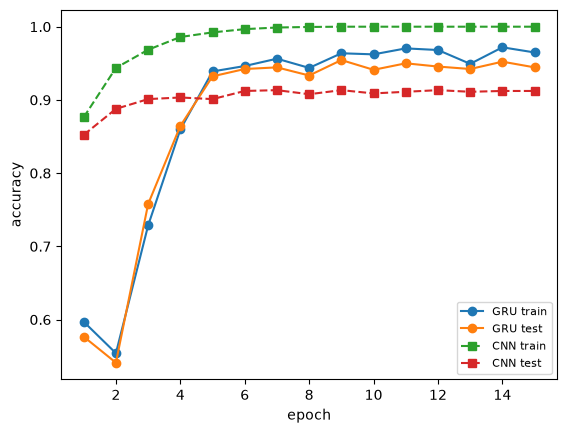

In [ ]:
summary = pd.DataFrame([
    {"model": "composition + logistic regression", "parameters": 63,
     "test accuracy": ACC_COMP, "featurization": "hand-crafted (counts)"},
    {"model": "dense net on flattened one-hot", "parameters": n_params(dense),
     "test accuracy": hist_dense["test accuracy"].iloc[-1], "featurization": "none (raw positions)"},
    {"model": "1-D CNN (16 filters, width 9)", "parameters": n_params(cnn),
     "test accuracy": ACC_CNN, "featurization": "learned local motifs"},
    {"model": "GRU (hidden 32)", "parameters": n_params(gru),
     "test accuracy": ACC_GRU, "featurization": "learned, order-aware"},
]).set_index("model")
display(summary)

ax = hist_gru[["train accuracy", "test accuracy"]].plot(marker="o")
hist_cnn[["train accuracy", "test accuracy"]].plot(marker="s", style="--", ax=ax)
ax.legend(["GRU train", "GRU test", "CNN train", "CNN test"], fontsize=8)
ax.set_ylabel("accuracy");

❓ The GRU wins (0.944 vs 0.912) with only 5283 parameters. What can it represent that the CNN
cannot? And look at the two training curves - which model is overfitting?

**Answer.** The CNN's global max-pooling deliberately **discards position and quantity**: it keeps
"the best match of each filter", and forgets where it was and whether there were three of them. The
GRU keeps a running state, so it can represent "a hydrophobic stretch *followed by* a small residue
near a cleavage site", "positive charges *and no* negative ones over the first 30 residues", or
simply "this started 40 residues ago, too late to be a signal". Order and composition together.
That extra 0.03 is the price of discarding position.

The curves show the CNN at train accuracy 1.000 from epoch 8 onwards while its test accuracy sits at
0.91 - it is memorising; the GRU ends at 0.965 on the training set, much closer to its test
accuracy of 0.944, so it still has room to learn rather than to memorise. Global
max-pooling makes a model that is easy to overfit on a dataset this small, because each class
decision rests on only 16 numbers.

Class 3 (Part 7) follows that further: it watches the GRU make up its mind residue by residue,
which a max-pooled CNN cannot show you.

## Part 5 - Control: does the order actually matter?

Both deep models beat the composition baseline. The obvious objection: maybe they are just better
*fitters* of the same information, and the "reading the sequence" story is decoration. There is a
clean experiment that settles it - **shuffle the residues inside each sequence**. Every composition
vector is untouched (a permutation does not change counts), so the baseline's accuracy cannot move
by a single protein. Only the order is destroyed.

✏️ **Exercise 5.1.** Build the shuffled one-hot tensor, retrain a fresh CNN and a fresh GRU on it
(same indices, same seeds, same epochs) and compare all four numbers.

original: MAWTPLLLLLLSHCTGSLSQPVLTQPPSSSASPGESARLTCTLPSDINVG
shuffled: SATLSSSCPLELTLCSMSTLVLAGLQQLTSISPPPRLGVTNPGAWSHDPL


,real sequences,shuffled residues,lost
composition + logreg,0.802,0.802,0.000
CNN,0.912,0.692,0.220
GRU,0.944,0.796,0.149


(on shuffled data the CNN still reaches train accuracy 0.995, the GRU 0.866)


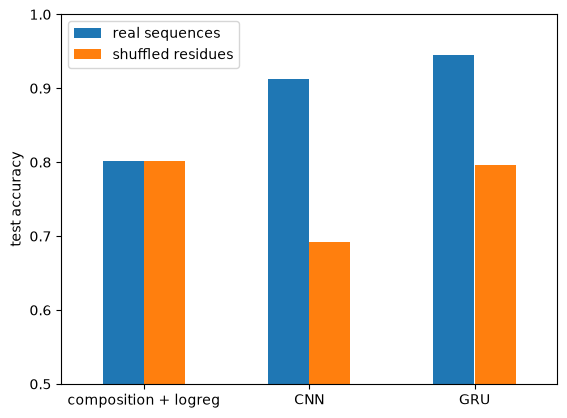

In [ ]:
rng = np.random.default_rng(RNG)
shuffled = tp["nterm"].map(lambda s: "".join(rng.permutation(list(s))))
print("original:", tp["nterm"].iloc[1])
print("shuffled:", shuffled.iloc[1])
assert np.allclose(aa_composition(tp["nterm"].iloc[1]), aa_composition(shuffled.iloc[1]))

X_shuf = torch.tensor(np.stack(shuffled.map(one_hot)))
torch.manual_seed(RNG)
hist_cnn_s = train(TargetingCNN(16, 9), X_shuf[idx_train], Y_train, X_shuf[idx_test], Y_test, epochs=15)
torch.manual_seed(RNG)
hist_gru_s = train(TargetingGRU(32), X_shuf[idx_train], Y_train, X_shuf[idx_test], Y_test, epochs=15)

control = pd.DataFrame({
    "real sequences": [ACC_COMP, ACC_CNN, ACC_GRU],
    "shuffled residues": [ACC_COMP,
                          hist_cnn_s["test accuracy"].iloc[-1],
                          hist_gru_s["test accuracy"].iloc[-1]],
}, index=["composition + logreg", "CNN", "GRU"])
control["lost"] = control["real sequences"] - control["shuffled residues"]
display(control.round(3))
print(f"(on shuffled data the CNN still reaches train accuracy "
      f"{hist_cnn_s['train accuracy'].iloc[-1]:.3f}, the GRU {hist_gru_s['train accuracy'].iloc[-1]:.3f})")

control[["real sequences", "shuffled residues"]].plot.bar(rot=0)
plt.ylabel("test accuracy"); plt.ylim(0.5, 1.0);

**Answer.** The GRU falls from 0.944 to **0.796** - back to the composition baseline (0.802), which
by construction has not moved at all. The entire ≈ 0.14 advantage of the recurrent network came from
the **order** of the residues, not from being a bigger model. This is the control that a referee
should ask for, and it is cheap.

The CNN falls further, to **0.692**, *below* the simple baseline, and that is worth a moment. Its
inductive bias - "the evidence is a 9-residue local motif, and I keep only the best one" - is a
**true** assumption about real N-termini and a **false** one about shuffled text. When the assumption
fails, the architecture that exploited it is actively harmed: max-pooling over 16 filters throws away
the counts that logistic regression used, and the model is left memorising (training accuracy 0.995,
test 0.692). An inductive bias is a bet; it pays when it matches the data and costs when it does not.

❓ Why does the GRU land *exactly* on the composition baseline rather than below it? Because a GRU
*can* approximate counting - a hidden unit that increments whenever it sees a leucine is a perfectly
good recurrent state. The architecture can fall back on composition; the max-pooled CNN cannot.

## Part 6 - Where this is going: attention and transformers

> *"Given enough examples, the network learns sequence and position-dependent features… the
> **attention mechanism**."* (deck pp. 36-46)

Our two sequence architectures each have a structural weakness, and both are about **range**:

* the **CNN** sees only inside its window - two residues 30 apart can never meet in one filter;
* the **GRU** can in principle connect them, but the information has to survive 30 sequential
  updates of a 32-dimensional state, and the 50 steps cannot be parallelised.

A **transformer** removes both limits with one idea. Instead of a fixed window or a running state,
every position computes, for every other position, a weight saying *how much to attend to it*, and
takes a weighted average of their representations. Range becomes unlimited, position enters through
an explicit positional encoding, and the whole thing is a few matrix multiplications - so it runs on
GPUs at a scale recurrence never could. Trained on the **masked-token task** (hide a residue, predict
it) over hundreds of millions of unlabelled sequences, it is the autoencoder idea of `extra04` pushed to its
limit: no labels, a learned representation as the by-product.

That is what **ESM-2**, **ProtBERT**, **ProteinBERT** and the rest are - the slides' "from sequences
to functions". The practical consequence for a biologist with 2000 labelled proteins is not that you
will train one; you will not. It is that you can **download the representation**: feed your sequences
through a frozen pretrained model, take the vectors it produces, and fit a small classifier - which
is precisely the enzyme problem that amino-acid composition cannot solve (class 2, Part B).

**`extra07` and `extra06` do exactly that.**

---

## Summary

* **Featurization** turns arbitrary objects into fixed-length vectors. Hand-crafted (amino-acid
  composition, 0.802 here) or **learned** - the whole argument of Part II of the deck.
* A **dense** net on flattened one-hot has 32 131 parameters, no weight sharing, and reaches 0.857:
  it must learn the same motif once per position.
* A **1-D CNN** with 2947 parameters reaches 0.912 by assuming local, translation-invariant motifs.
  Inspecting its 16 filters shows that it rediscovered the **hydrophobic h-region** (r = 0.93 with the
  Kyte-Doolittle scale, voting SP) and the **Arg-rich transit peptide**, from labels alone.
* A **GRU** with 5283 parameters reaches 0.944 because it keeps order *and* composition, and it can
  tell you after how many residues it decided (class 3, Part 7).
* The **shuffling control** proves the gain is real: the GRU drops to 0.796, the composition baseline
  does not move, and the CNN falls to 0.692 - an inductive bias costs you when it is wrong.
* **Transformers** generalise the "learn the representation without labels" idea to a scale where the
  representation becomes a reusable resource - the subject of `extra07`.

### If you have time

✏️ **A.** Stack a second convolution on top of the first (`Conv1d(16, 16, 5)` with a ReLU in between,
then global max-pooling). Does a two-layer CNN beat the one-layer one here? Why might depth help less
on 50-residue windows than on ImageNet photographs?

✏️ **B.** Make the GRU **bidirectional** (`nn.GRU(..., bidirectional=True)`, head input `2*hidden`,
concatenate the two final states). Real tools - TargetP 2.0, SignalP 6.0 - do this. How much does it
gain, and at what cost in parameters and time?

✏️ **C.** Train the CNN on all organisms **except human** and test on the human proteins
(`tp["organism"] == "Homo sapiens"`). Compare with the random split. Does a learned filter transfer
across species?

## References and data sources

**Data**

* `data/targeting.tsv` and `data/enzymes.tsv`: reviewed entries of UniProtKB/Swiss-Prot (UniProt
  Consortium 2023), downloaded with the UniProt REST API from human, *E. coli* K-12,
  *S. cerevisiae*, *A. thaliana* and *B. subtilis*; Swiss-Prot changes at every release, so the
  committed TSVs are the reference. Targeting labels come from the `SIGNAL` and `TRANSIT` feature
  annotations; see `README.md` and `data_prep/`.
* Kyte J, Doolittle RF (1982). A simple method for displaying the hydropathic character of a protein.
  *J Mol Biol* 157:105-132. [doi:10.1016/0022-2836(82)90515-0](https://doi.org/10.1016/0022-2836(82)90515-0)
  — the hydropathy scale used (only) to interpret the learned filters

**Architectures**

* LeCun Y, Bottou L, Bengio Y, Haffner P (1998). Gradient-based learning applied to document
  recognition. *Proc IEEE* 86:2278-2324. [doi:10.1109/5.726791](https://doi.org/10.1109/5.726791)
  — convolutional networks, weight sharing and pooling
* Krizhevsky A, Sutskever I, Hinton GE (2012). ImageNet classification with deep convolutional neural
  networks. *NeurIPS 25*. [proceedings link](https://papers.nips.cc/paper/4824) — AlexNet, the slide's
  example of learned features
* Cho K, van Merriënboer B, Gulcehre C, et al. (2014). Learning phrase representations using RNN
  encoder-decoder for statistical machine translation. *Proc EMNLP* 1724-1734.
  [doi:10.3115/v1/D14-1179](https://doi.org/10.3115/v1/D14-1179) — the GRU
* Vaswani A, Shazeer N, Parmar N, et al. (2017). Attention is all you need. *NeurIPS 30*.
  [arXiv:1706.03762](https://arxiv.org/abs/1706.03762) — the transformer
* Alipanahi B, Delong A, Weirauch MT, Frey BJ (2015). Predicting the sequence specificities of DNA-
  and RNA-binding proteins by deep learning. *Nat Biotechnol* 33:831-838.
  [doi:10.1038/nbt.3300](https://doi.org/10.1038/nbt.3300) — DeepBind: the "read the learned filters
  as motifs" analysis of Part 3, for nucleic acids

**The biology, and what the real predictors do**

* von Heijne G (1985). Signal sequences: the limits of variation. *J Mol Biol* 184:99-105.
  [doi:10.1016/0022-2836(85)90046-4](https://doi.org/10.1016/0022-2836(85)90046-4) — the n/h/c-region
  description of signal peptides that our filters rediscover
* Almagro Armenteros JJ, Salvatore M, Emanuelsson O, et al. (2019). Detecting sequence signals in
  targeting peptides using deep learning. *Life Sci Alliance* 2:e201900429.
  [doi:10.26508/lsa.201900429](https://doi.org/10.26508/lsa.201900429) — TargetP 2.0, a bidirectional
  LSTM on these same three classes
* Teufel F, Almagro Armenteros JJ, Johansen AR, et al. (2022). SignalP 6.0 predicts all five types of
  signal peptides using protein language models. *Nat Biotechnol* 40:1023-1025.
  [doi:10.1038/s41587-021-01156-3](https://doi.org/10.1038/s41587-021-01156-3)

**Slides**

* `slides/ai-qbio-unimi_2026_r1.pdf`, Part II "Advanced ANN architectures", pages 27-46.